In [ ]:
from pathlib import Path
import torch

In [2]:
tensor_0d = torch.tensor(0)
tensor_1d = torch.tensor([0])
tensor_2d = torch.tensor([[1,2],[3,4]])
tensor_3d = torch.tensor([[[1,2],[3,4]],[[5,6],[7,8]]])

In [4]:
print(tensor_3d.dtype)

torch.int64


In [5]:
tensor2d = torch.tensor([[1,2,3],
                         [4,5,6]])
tensor2d

tensor([[1, 2, 3],
        [4, 5, 6]])

In [6]:
tensor2d.shape

torch.Size([2, 3])

In [7]:
tensor2d.reshape(3,2)
# tensor2d.view(3, 2) more common command for reshaping tensors

tensor([[1, 2],
        [3, 4],
        [5, 6]])

In [10]:
tensor2d.T

tensor([[1, 4],
        [2, 5],
        [3, 6]])

In [12]:
# common way to multiply two matrices in PyTorch is the .matmul method
tensor2d.matmul(tensor2d.T)

tensor([[14, 32],
        [32, 77]])

In [13]:
tensor2d @ tensor2d.T

tensor([[14, 32],
        [32, 77]])

In [14]:
# PyTorch’s automatic differentiation engine, also known as autograd provides functions to compute gradients in dynamic computational graphs automatically.
# A computational graph (or computation graph in short) is a directed graph that allows us to express and visualize mathematical expressions. 
# In the context of deep learning, a computation graph lays out the sequence of calculations needed to compute the output of a neural network.

import torch.nn.functional as F

y = torch.tensor([1.0])
x = torch.tensor([1.1])
w = torch.tensor([2.2])
b = torch.tensor([0.0])

z = w * x + b
a = torch.sigmoid(z)

loss = F.binary_cross_entropy(a, y)
print(loss)

tensor(0.0852)


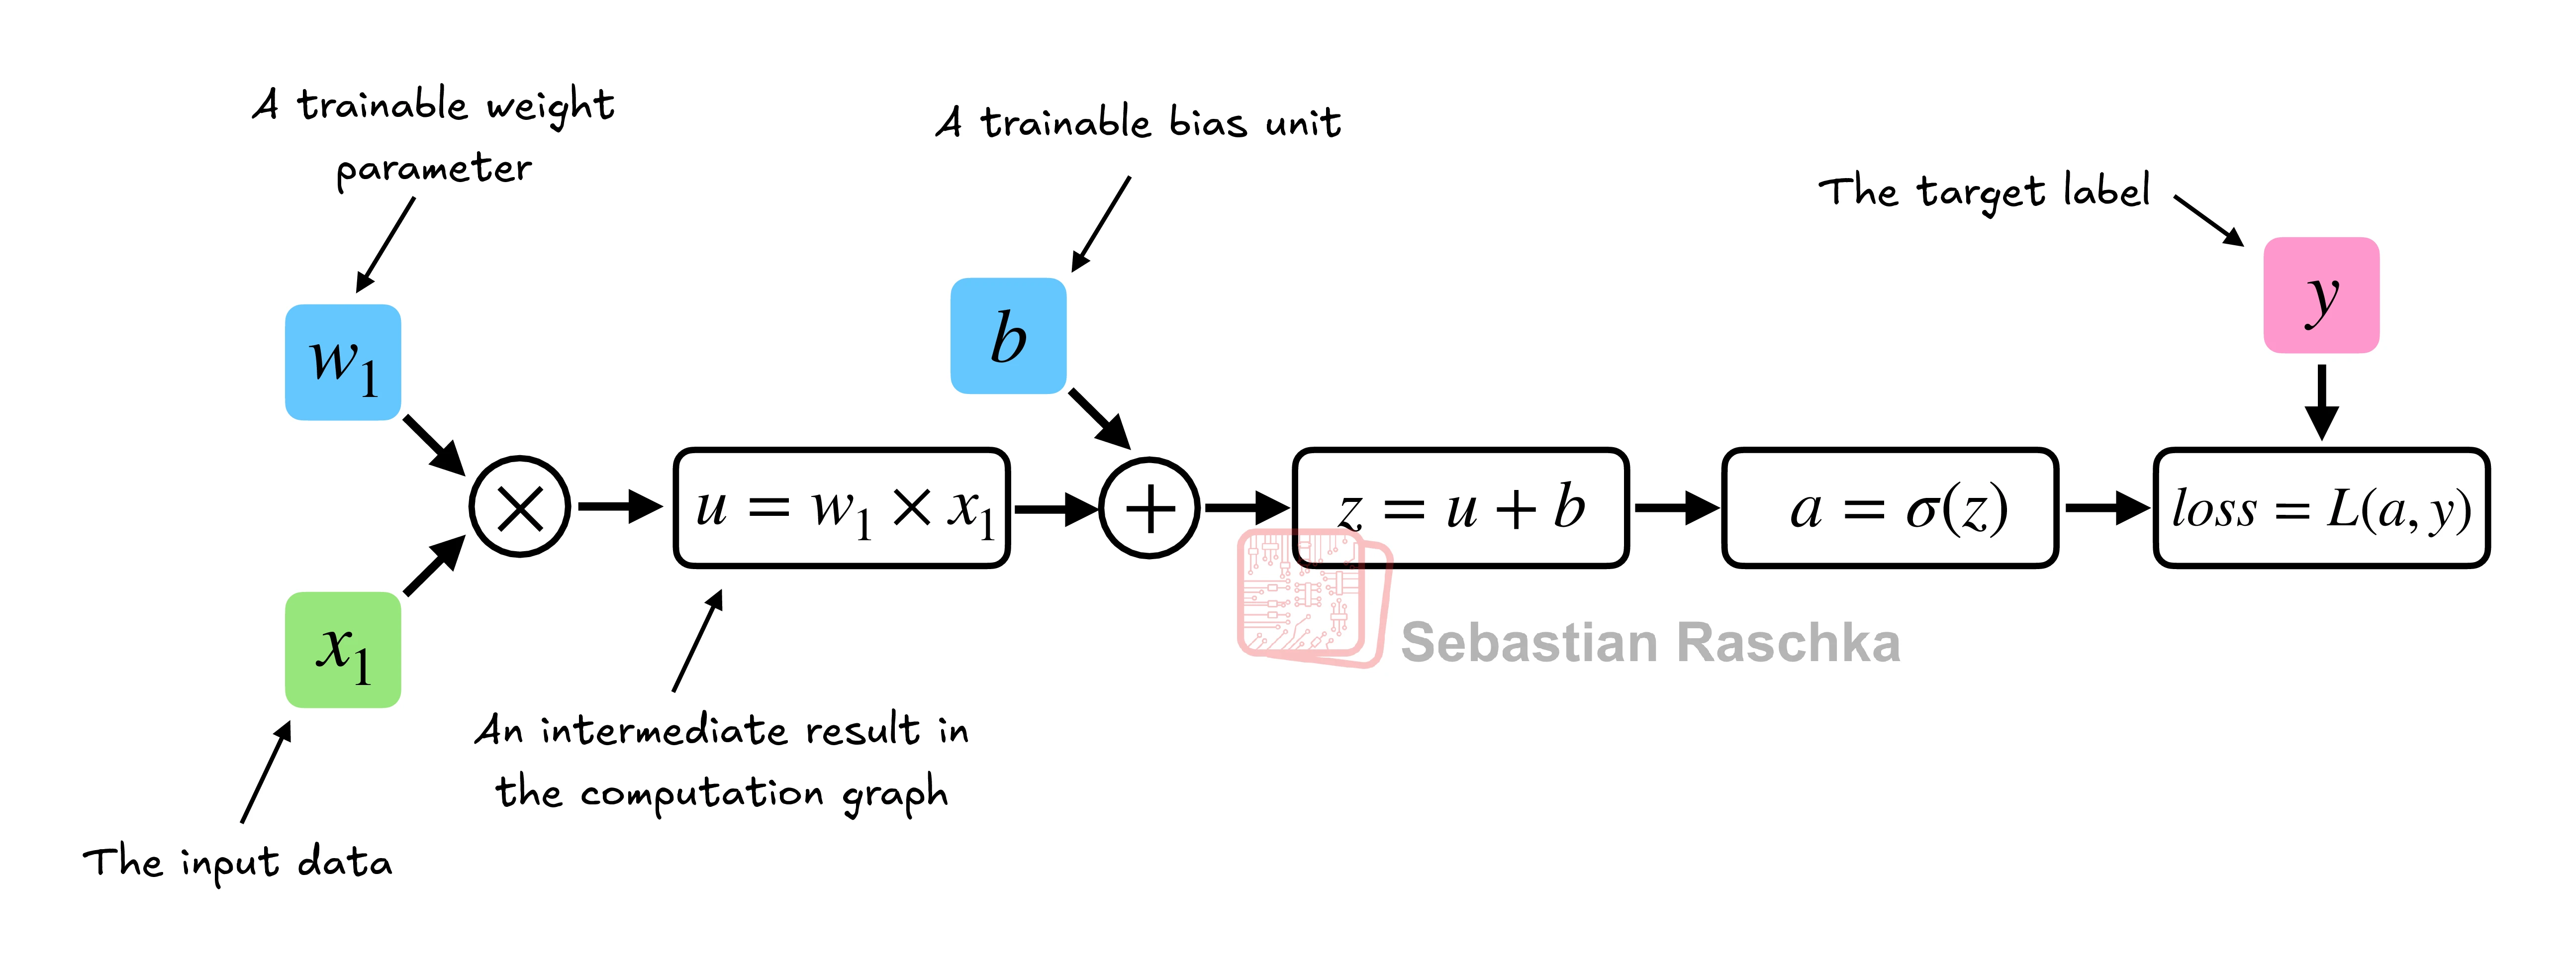

###### PyTorch builds such a computation graph in the background, and we can use this to calculate gradients of a loss function with respect to the model parameters (here w1 and b) to train the model.
###### If one of its terminal nodes has the requires_grad attribute set to True, it will build such a graph internally by default. This is useful if we want to compute gradients.
###### Gradients are required when training neural networks via the popular backpropagation algorithm, which can be thought of as an implementation of the chain rule from calculus for neural networks.

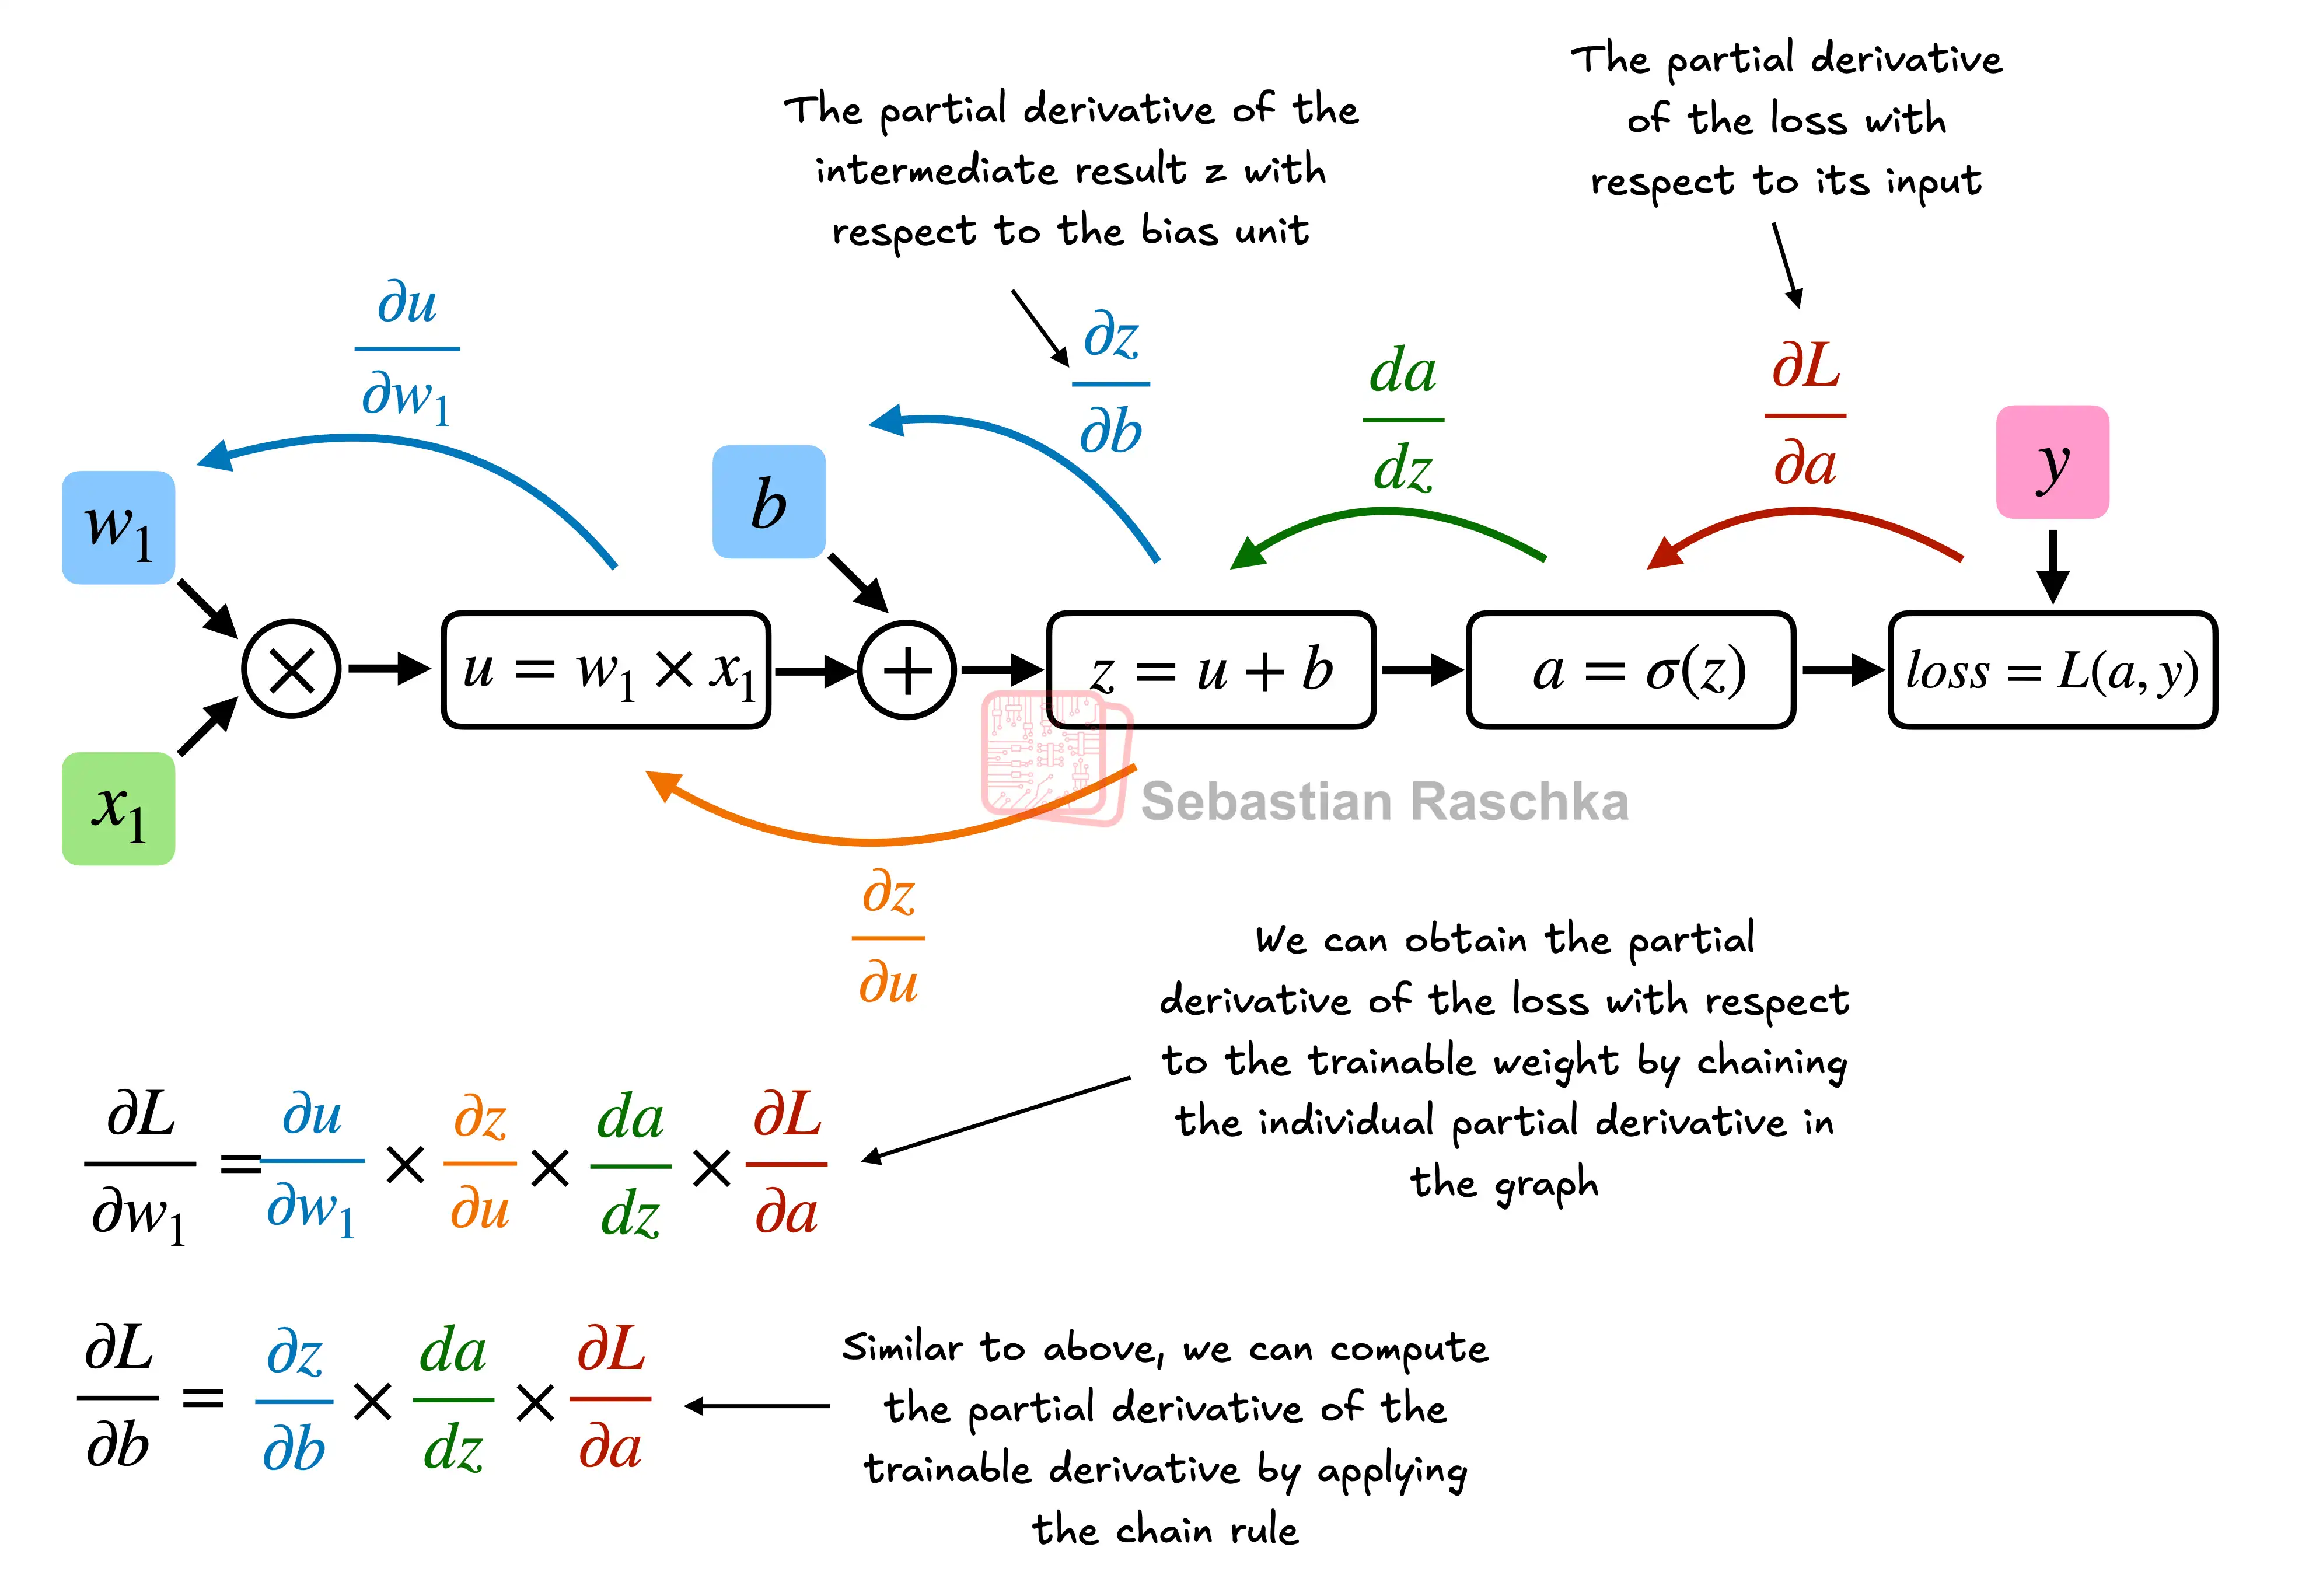


In [16]:
import torch.nn.functional as F
from torch.autograd import grad

y = torch.tensor([1.0])
x1 = torch.tensor([1.1])
w1 = torch.tensor([2.2], requires_grad=True)
b = torch.tensor([0.0], requires_grad=True)

z = x1 * w1 + b
a = torch.sigmoid(z)

loss = F.binary_cross_entropy(a, y)

grad_L_w1 = grad(loss, w1, retain_graph=True)
grad_L_b = grad(loss, b, retain_graph=True)

print(grad_L_w1)
print(grad_L_b)

# Since we are going to reuse this computation graph shortly, we set retain_graph=True so that it stays in memory.


(tensor([-0.0898]),)
(tensor([-0.0817]),)


In [17]:
# in practice, PyTorch provides even more high-level tools to automate this process. 
# For instance, we can call .backward on the loss, and PyTorch will compute the gradients of all the leaf nodes in the graph, which will be stored via the tensors’ .grad attributes.

loss.backward()

print(w1.grad)
print(b.grad)


tensor([-0.0898])
tensor([-0.0817])


In [20]:
# If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor.
a.retain_grad()
print(a.grad)

None


#### Implementing multilayer neural networks

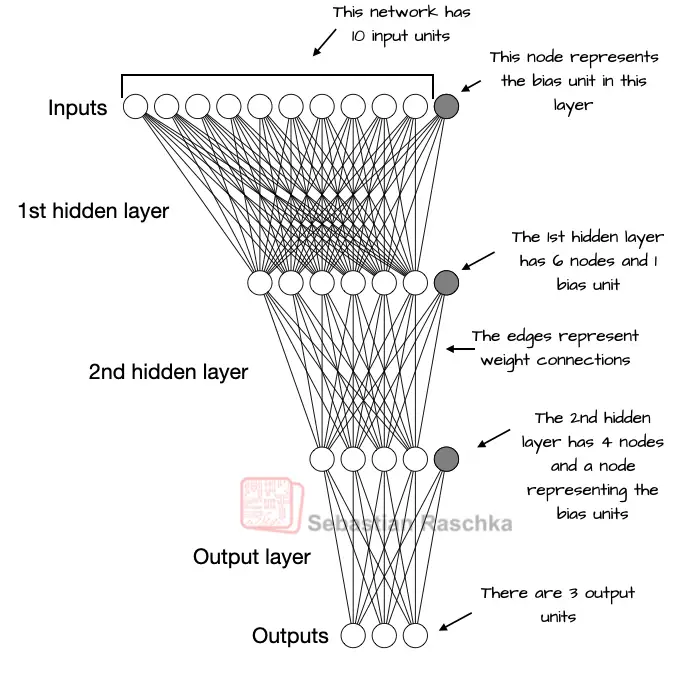

###### When implementing a neural network in PyTorch, we typically subclass the torch.nn.Module class to define our own custom network architecture.
###### Within this subclass, we define the network layers in the __init__ constructor and specify how they interact in the forward method. The forward method describes how the input data passes through the network and comes together as a computation graph.

In [21]:
class NeuralNetwork(torch.nn.Module):
    def __init__(self, num_inputs, num_outputs):
        super().__init__()
        self.layers = torch.nn.Sequential(
            #1st hidden layer
            torch.nn.Linear(num_inputs, 30),
            torch.nn.ReLU(),

            #2nd hidden layer
            torch.nn.Linear(30, 20),
            torch.nn.ReLU(),

            # output layer
            torch.nn.Linear(20, num_outputs)
        )

    def forward(self, x):
        logits = self.layers(x)
        return logits

In [23]:
model = NeuralNetwork(50, 3)
print(model)
# The first Linear layer is at index position 0 in the layers attribute.

NeuralNetwork(
  (layers): Sequential(
    (0): Linear(in_features=50, out_features=30, bias=True)
    (1): ReLU()
    (2): Linear(in_features=30, out_features=20, bias=True)
    (3): ReLU()
    (4): Linear(in_features=20, out_features=3, bias=True)
  )
)


In [25]:
# The total number of trainable parameters of this model
total_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
    )
print("Total number of trainable model parameters:", total_params)

Total number of trainable model parameters: 2213


In [27]:
print(model.layers[0].weight)
print(model.layers[0].weight.shape)

Parameter containing:
tensor([[-0.0085, -0.0530,  0.0270,  ...,  0.0409, -0.0255,  0.0588],
        [-0.0417, -0.0253,  0.0607,  ..., -0.0153, -0.1367,  0.0945],
        [-0.0362, -0.1102,  0.0701,  ..., -0.1020, -0.0553, -0.1302],
        ...,
        [-0.0081,  0.1364,  0.0497,  ..., -0.1303,  0.0394, -0.0452],
        [-0.1411, -0.0645,  0.0740,  ..., -0.0795,  0.0589,  0.0266],
        [ 0.0687,  0.0496, -0.0466,  ..., -0.1213, -0.0957, -0.0764]],
       requires_grad=True)
torch.Size([30, 50])


In [28]:
# The model weights are initialized with small random numbers, which are different each time we instantiate the network.
# Initializing model weights with small random numbers is desired to break symmetry during training.
# Otherwise, the nodes would be just performing the same operations and updates during backpropagation, which would not allow the network to learn complex mappings from inputs to outputs.
# We can make the random number initialization reproducible by seeding PyTorch’s random number generator via manual_seed

torch.manual_seed(123)

model = NeuralNetwork(50, 3)
print(model.layers[0].weight)

Parameter containing:
tensor([[-0.0577,  0.0047, -0.0702,  ...,  0.0222,  0.1260,  0.0865],
        [ 0.0502,  0.0307,  0.0333,  ...,  0.0951,  0.1134, -0.0297],
        [ 0.1077, -0.1108,  0.0122,  ...,  0.0108, -0.1049, -0.1063],
        ...,
        [-0.0787,  0.1259,  0.0803,  ...,  0.1218,  0.1303, -0.1351],
        [ 0.1359,  0.0175, -0.0673,  ...,  0.0674,  0.0676,  0.1058],
        [ 0.0790,  0.1343, -0.0293,  ...,  0.0344, -0.0971, -0.0509]],
       requires_grad=True)


In [29]:
# Let's generate a single random training example X as a toy input (note that our network expects 50-dimensional feature vectors) and fed it to the model, returning three scores.

torch.manual_seed(123)

X = torch.rand((1, 50))
out = model(X)
print(out)

# Here, grad_fn=<AddmmBackward0> represents the last-used function to compute a variable in the computational graph. 
# In particular, grad_fn=<AddmmBackward0> means that the tensor we are inspecting was created via a matrix multiplication and addition operation. 
# PyTorch will use this information when it computes gradients during backpropagation. 
# The <AddmmBackward0> part of grad_fn=<AddmmBackward0> specifies the operation that was performed. 
# In this case, it is an Addmm operation. Addmm stands for matrix multiplication (mm) followed by an addition (Add).


tensor([[-0.1262,  0.1080, -0.1792]], grad_fn=<AddmmBackward0>)


In [30]:
# When we use a model for inference (for instance, making predictions) rather than training, it is a best practice to use the torch.no_grad() context manager.
with torch.no_grad():
    out = model(X)
print(out)

tensor([[-0.1262,  0.1080, -0.1792]])


In [32]:
# In PyTorch, it’s common practice to code models such that they return the outputs of the last layer (logits) without passing them to a nonlinear activation function. 
# PyTorch’s commonly used loss functions combine the softmax (or sigmoid for binary classification) operation with the negative log-likelihood loss in a single class. 
# The reason for this is numerical efficiency and stability. 
# So, if we want to compute class-membership probabilities for our predictions, we have to call the softmax function explicitly
with torch.no_grad():
    out = torch.softmax(model(X), dim=1)
print(out)

# The values can now be interpreted as class-membership probabilities that sum up to 1.

tensor([[0.3113, 0.3934, 0.2952]])


In [33]:
X_train = torch.tensor([
    [-1.2, 3.1],
    [-0.9, 2.9],
    [-0.5, 2.6],
    [2.3, -1.1],
    [2.7, -1.5]
])

y_train = torch.tensor([0, 0, 0, 1, 1])

X_test = torch.tensor([
    [-0.8, 2.8],
    [2.6, -1.6],
])

y_test = torch.tensor([0, 1])

from torch.utils.data import Dataset

class ToyDataset(Dataset):
    def __init__(self, X, y):
        self.features = X
        self.labels = y

    def __getitem__(self, index):
        one_x = self.features[index]
        one_y = self.labels[index]
        return one_x, one_y

    def __len__(self):
        return self.labels.shape[0]

train_ds = ToyDataset(X_train, y_train)
test_ds = ToyDataset(X_test, y_test)

from torch.utils.data import DataLoader

torch.manual_seed(123)

train_loader = DataLoader(
    dataset=train_ds,
    batch_size=2,
    shuffle=True,
    num_workers=0
)

test_ds = ToyDataset(X_test, y_test)

test_loader = DataLoader(
    dataset=test_ds,
    batch_size=2,
    shuffle=False,
    num_workers=0
)

In [34]:
for idx, (x, y) in enumerate(train_loader):
    print(f"Batch {idx+1}:", x, y)

Batch 1: tensor([[ 2.3000, -1.1000],
        [-0.9000,  2.9000]]) tensor([1, 0])
Batch 2: tensor([[-1.2000,  3.1000],
        [-0.5000,  2.6000]]) tensor([0, 0])
Batch 3: tensor([[ 2.7000, -1.5000]]) tensor([1])


In [35]:
train_loader = DataLoader(
    dataset=train_ds,
    batch_size=2,
    shuffle=True,
    num_workers=0,
    drop_last=True
)

In [36]:
# A typical training loop for a PyTorch model involves iterating over the dataset multiple times (epochs), computing the loss, performing backpropagation, and updating the model parameters using an optimizer.

import torch.nn.functional as F

torch.manual_seed(123)
model = NeuralNetwork(num_inputs=2, num_outputs=2)
optimizer = torch.optim.SGD(model.parameters(), lr=0.5)

num_epochs = 3

for epoch in range(num_epochs):

    model.train()
    for batch_idx, (features, labels) in enumerate(train_loader):

        logits = model(features)

        loss = F.cross_entropy(logits, labels) # compute cross-entropy loss between predicted logits and true labels

        optimizer.zero_grad() # clear previous gradients
        loss.backward() # backward pass to compute gradients
        optimizer.step() # update model parameters based on computed gradients

        ### LOGGING
        print(f"Epoch: {epoch+1:03d}/{num_epochs:03d}"
              f" | Batch {batch_idx:03d}/{len(train_loader):03d}"
              f" | Train/Val Loss: {loss:.2f}")

    # Optional model evaluation
    model.eval()

# We used a stochastic gradient descent (SGD) optimizer with a learning rate (lr) of 0.5. The learning rate is a hyperparameter, meaning it’s a tunable setting that we have to experiment with based on observing the loss.
# We also introduced new settings called model.train() and model.eval(). As these names imply, these settings are used to put the model into a training and an evaluation mode. This is necessary for components that behave differently during training and inference, such as dropout or batch normalization layers.
# we pass the logits directly into the cross_entropy loss function, which will apply the softmax function internally for efficiency and numerical stability reasons.
# Then, calling loss.backward() will calculate the gradients in the computation graph that PyTorch constructed in the background. 
# The optimizer.step() method will use the gradients to update the model parameters to minimize the loss. 
# In the case of the SGD optimizer, this means multiplying the gradients with the learning rate and adding the scaled negative gradient to the parameters.

Epoch: 001/003 | Batch 000/002 | Train/Val Loss: 0.75
Epoch: 001/003 | Batch 001/002 | Train/Val Loss: 0.65
Epoch: 002/003 | Batch 000/002 | Train/Val Loss: 0.44
Epoch: 002/003 | Batch 001/002 | Train/Val Loss: 0.13
Epoch: 003/003 | Batch 000/002 | Train/Val Loss: 0.03
Epoch: 003/003 | Batch 001/002 | Train/Val Loss: 0.00


In [37]:
# After training the model, we can use it to make predictions
model.eval()

with torch.no_grad():
    outputs = model(X_train)

print(outputs)

tensor([[ 2.8569, -4.1618],
        [ 2.5382, -3.7548],
        [ 2.0944, -3.1820],
        [-1.4814,  1.4816],
        [-1.7176,  1.7342]])


In [38]:
# To obtain the class membership probabilities, we can then use PyTorch’s softmax function.
torch.set_printoptions(sci_mode=False)
probas = torch.softmax(outputs, dim=1)
print(probas)

tensor([[0.9991, 0.0009],
        [0.9982, 0.0018],
        [0.9949, 0.0051],
        [0.0491, 0.9509],
        [0.0307, 0.9693]])


In [39]:
# We can convert these values into class labels predictions using PyTorch’s argmax function, which returns the index position of the highest value in each row if we set dim=1 (setting dim=0 would return the highest value in each column, instead):
predictions = torch.argmax(probas, dim=1)
print(predictions)

tensor([0, 0, 0, 1, 1])


In [40]:
predictions = torch.argmax(outputs, dim=1)
print(predictions)

tensor([0, 0, 0, 1, 1])


In [41]:
predictions == y_train

tensor([True, True, True, True, True])

In [42]:
torch.sum(predictions == y_train)

tensor(5)

##### Save and load models in PyTorch

In [43]:
# save and load models in PyTorch
torch.save(model.state_dict(), "model.pth")

In [44]:
model = NeuralNetwork(2, 2) # needs to match the original model exactly
model.load_state_dict(torch.load("model.pth", weights_only=True))

# model = NeuralNetwork(2, 2) above is not strictly necessary if you execute this code in the same session where you saved a model.
# Here, the NeuralNetwork(2, 2) architecture needs to match the original saved model exactly

<All keys matched successfully>